In [1]:
import cobra
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import spearmanr
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)
gem2seed = pd.read_csv('../../Expression_datasets/model_reaction_to_seed_reaction_mapping.csv')
Ecoli = cobra.io.load_json_model('../../Expression_datasets/mori_msb/iML1515.json')

In [3]:
Ecoli_gpr = []
for rec in Ecoli.reactions:

    seedrec = rec.annotation.get('seed.reaction')
    if seedrec is None:
        continue

    seedrec = seedrec[0]

    if len(rec.genes) > 0:
        gene_id = [gene.id for gene in list(rec.genes) if gene.id not in ['Unknown']]
        Ecoli_gpr.append((seedrec, gene_id))
Ecoli_gpr = pd.DataFrame(Ecoli_gpr, columns=['Model_Reaction_ID', 'Gene_IDs'])

In [4]:
cluster_genes = {}
for idx, group in cluster_nodes.items():
    for rec in group:
        rec2seed = gem2seed[gem2seed['Model_Reaction_ID'] == rec[:-4]]['SEED_Reaction_ID'].values
        rec2seed = rec2seed[0] if len(rec2seed) > 0 else None
        if rec2seed is not None:
            rec2gene = Ecoli_gpr[Ecoli_gpr['Model_Reaction_ID'] == rec2seed]['Gene_IDs'].values
            rec2gene = rec2gene[0] if len(rec2gene) > 0 else None
            if rec2gene is not None:
                if idx not in cluster_genes:
                    cluster_genes[idx] = []
                for gene in rec2gene:
                    cluster_genes[idx].append(gene)

In [5]:
Ecoli_trans_data = pd.read_excel('../../Expression_datasets/mori_msb/Expression.xlsx', sheet_name='EV9-AbsoluteMassFractions-2')
gr = pd.read_excel('../../Expression_datasets/mori_msb/growth.xlsx', sheet_name='EV3-Samples-2')
gr = gr['Growth rate (1/h)']

In [6]:
n_samples = Ecoli_trans_data.shape[1] - 1
overall_value = np.zeros((len(cluster_nodes), n_samples)) 

for idx, group in cluster_genes.items():

    group_value = np.zeros(n_samples)

    for gene in group:
        gene_count = sum(gene in g for g in cluster_genes.values())

        gene_value = Ecoli_trans_data[Ecoli_trans_data['Gene locus'] == gene].iloc[:, 1:].values

        if gene_value.size == 0:
            continue

        gene_value = np.array(gene_value[0]) / gene_count

        group_value += gene_value

    overall_value[idx, :] = group_value

norm_overall_value = overall_value / np.sum(overall_value, axis=0)

In [7]:
corr_ecoli = []

for i in range(20):
    corr = spearmanr(norm_overall_value[i], gr)
    corr_ecoli.append((corr.correlation))

with open('../Figure4/corr_ecoli_palsson.pkl', 'rb') as f:
    corr_ecoli_palsson = pickle.load(f)
    corr_ecoli_palsson = np.array(corr_ecoli_palsson)[:, 0]

/home/complicatedz/miniconda3/envs/autopacman/lib/python3.8/site-packages/scipy/stats/_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))


{'r': 0.7228003954366723, 'p': 0.0004721042125951671, 'ci_low': 0.3998692413567444, 'ci_high': 0.8861005285373974, 'n': 19}


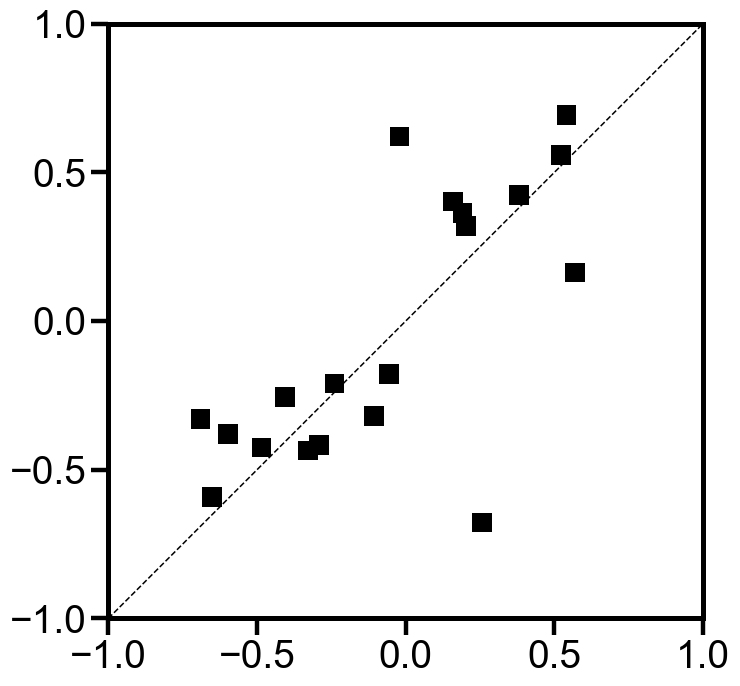

In [ ]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    corr_ecoli_palsson[:19], corr_ecoli[:19],
    s=200,
    color="black",
    edgecolors="none",
    marker='s'
)

ax.set_box_aspect(1)

ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_yticks(np.arange(-1, 1.01, 0.5))
xmin, xmax = ax.get_xlim()
ax.plot([xmin, xmax], [xmin, xmax], linestyle="--", color="black", linewidth=1.1, alpha=1)

ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)

print(pearson_ci(corr_ecoli_palsson, corr_ecoli, confidence=0.95))
plt.tight_layout()
plt.show()
